<a href="https://colab.research.google.com/github/anvitha5456-creator/ML_LAB_2026-27/blob/main/Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TITANIC SURVIVAL PREDICTION USING CLASSIFICATION ALGORITHMS
Mini Project – Machine Learning

This project predicts whether a Titanic passenger survived or not using passenger details.

Target classes:
- 0 – Did not survive
- 1 – Survived
We use the same four classification algorithms as the reference project:
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Support Vector Machine (SVM)

Step 1: Import **libraries**

In [19]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("All libraries imported successfully!")

All libraries imported successfully!


Step 2: Load the dataset

In [20]:
# Load Titanic Dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

# Display first 5 rows
print(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Dataset Shape: (891, 15)


Step 3: Data preprocessing

In [21]:
# Select input features

X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]

# Select target variable

y = df['survived']

# Display input features
print("Input Features:")
print(X.head())

# Display target variable
print("\nTarget Variable:")
print(y.head())

# Check missing values
print("\nMissing Values:")
print(X.isnull().sum())

Input Features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target Variable:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64

Missing Values:
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


Step 4: Split the dataset

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 7)
Testing Data: (179, 7)


Step 5: Preprocessing numerical and categorical data

In [23]:
# Numerical features
numeric_features = ['pclass', 'age', 'sibsp', 'parch', 'fare']

# Categorical features
categorical_features = ['sex', 'embarked']

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

Step 6: Logistic Regression

In [24]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.8044692737430168
LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



Step 7: Decision Tree

In [25]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=15,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))
print("DECISION TREE")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.8268156424581006
DECISION TREE
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



Step 8: K-Nearest Neighbors (KNN)

In [26]:
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))
print("KNN")
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.8156424581005587
KNN
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



Step 9: Support Vector Machine (SVM)

In [27]:
svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred))
print("SVM")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.7932960893854749
SVM
              precision    recall  f1-score   support

           0       0.81      0.87      0.84       110
           1       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



Step 10: Compare all four algorithms

In [28]:
results = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ]
})

print(results)

             Algorithm  Accuracy
0  Logistic Regression  0.804469
1        Decision Tree  0.826816
2                  KNN  0.815642
3                  SVM  0.793296


Step 11: Visualize accuracy comparison

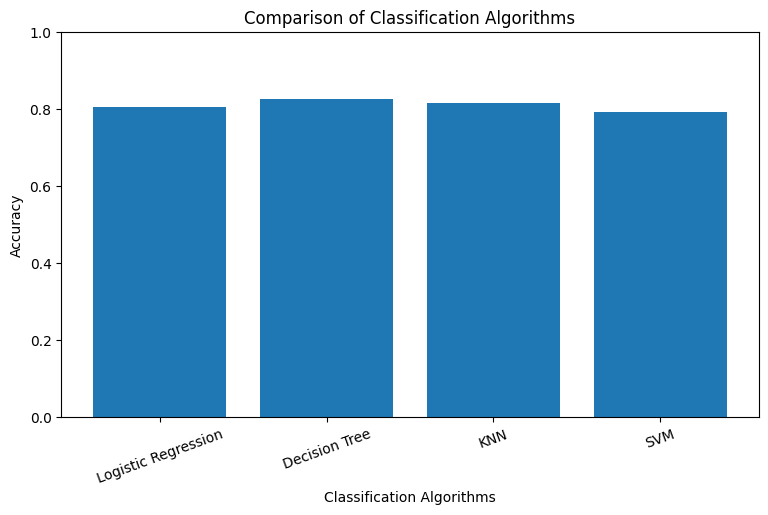

In [29]:
plt.figure(figsize=(9, 5))
plt.bar(results['Algorithm'], results['Accuracy'])
plt.xlabel('Classification Algorithms')
plt.ylabel('Accuracy')
plt.title('Comparison of Classification Algorithms')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

Step 12: Confusion matrices

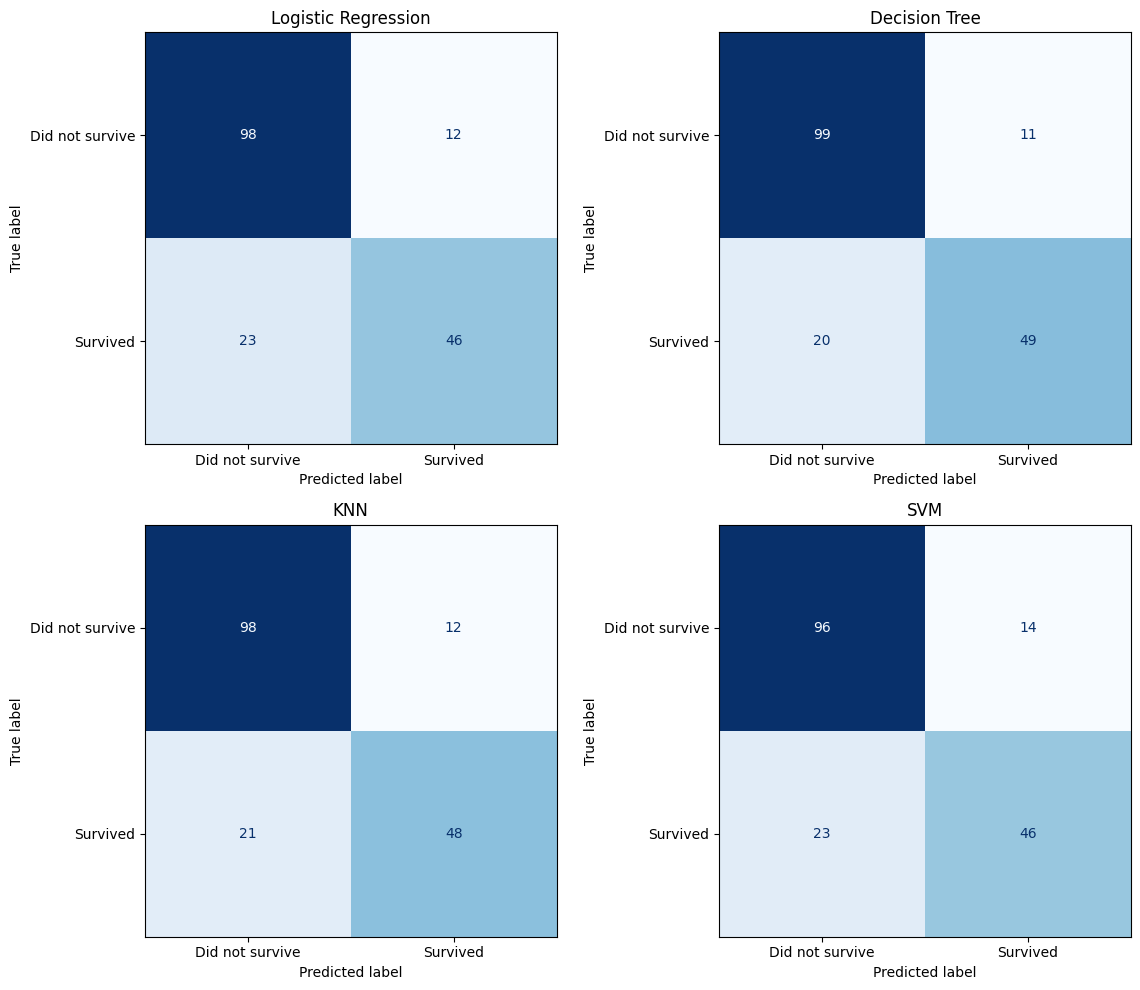

In [30]:
models = {
    'Logistic Regression': lr_pred,
    'Decision Tree': dt_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

labels = [0, 1]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, predictions) in enumerate(models.items()):
    cm = confusion_matrix(y_test, predictions, labels=labels)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Did not survive', 'Survived']
    )

    display.plot(
        ax=axes[i],
        cmap='Blues',
        values_format='d',
        colorbar=False
    )
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

Conclusion
In this project, we used the Titanic passenger dataset to predict passenger survival. We applied four classification algorithms: Logistic Regression, Decision Tree, KNN, and SVM. We evaluated their performance using accuracy, classification reports, and confusion matrices.

The accuracy comparison helps us identify which of the four algorithms performed best on this test dataset.